# G93 Integrative Project - KPIs and Statistical Analysis

In this notebook, we will analyze everything related to the "Stations_Data.csv" file. The .csv file contains these variables:

- **Station**: {Berlin, Hamburg, Hannover, Frankfurt, Stuttgart}
- **Year**: (2015–2024)
- **Month**: (1–12)
- **Arrival of trains**: number
- **Iron**: tons
- **Coal**: tons
- **Steel**: tons
- **Vegetables**: tons
- **Cereals**: tons
- **Wool**: tons
- **Coffee**: tons
- **Cattle**: tons
- **Passengers**: number
- **Mail**: tons
- **Revenues**: Millions (€)
- **Expenses**: Millions (€)

The analysis will be divided into 4 user storys (US), which are the following:

1. **US15 - As a Player, I want to perform a statistical analysis of the aver age annual profit of a user-specified railway station.**
2. **US16 - As a Player, I want to perform a comparative analysis of passenger arrivals across all stations.**
3. **US17 - As a Player, I want to perform an analysis of the cargo arriving at each station using all recorded data.**
4. **US18 - As a Player, I want to perform the analysis of train distribution, passengers, and mail across different stations**

In each section (dedicated to one US), there will be a theoretical explanation about the statistical concepts that will be used, alongside the Python code to obtain the results.

## **US15: Statistical Analysis of the average annual profit of a user-specified railway station**

### **User Story Details**

As a Player, I want to perform a statistical analysis of the average annual profit of a user-specified railway station. In order to achieve this, a table with key descriptive measures: mean, standard deviation, median, and mode will be generated. Additionally, the analysis aims to identify outlier profits as well as to determine the most and least profitable years.

### **Theoretical Explanation**

#### What is a mean?

It's a quantity representing the "center" of a collection of numbers and is intermediate to the extreme values of the set of numbers.

#### What is a standard deviation?

It's a measure of the amount of variation of the values of a variable about its mean.

#### What is a median?

It's a set of numbers is the value separating the higher half from the lower half of a data sample, a population, or a probability distribution.

#### What is a mode?

It's a way of expressing, in a (usually) single number, important information about a random variable or a population.

#### What is an outlier?

It's a data point that differs significantly from other observations.

### **Code for US15**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('Stations_Data.csv', sep=';')

# Convert values to float
num_cols = [
    'Revenues', 'Expenses'
]

for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.', regex=False),
        errors='coerce'
    )

# Obtain annual profit
df['Profit'] = df['Revenues'] - df['Expenses']
annual_profit = (
    df
    .groupby(['Station', 'Year'], as_index=False)['Profit']
    .sum()
)

# Input
station = input("Insert the station's name: ").strip()
station_data = annual_profit[annual_profit['Station'] == station]

if station_data.empty:
    print(f"No data found for station '{station}'.")
else:
    profits = station_data['Profit']
    years = station_data['Year']
    
    # Descriptive measures
    mean = profits.mean()
    std = profits.std()
    median = profits.median()
    mode = profits.mode().iloc[0] if not profits.mode().empty else None
    
    print(f"\nDescriptive measures for station: '{station}':")
    print(f"Mean: {mean:.2f}")
    print(f"Standard deviation: {std:.2f}")
    print(f"Median: {median:.2f}")
    print(f"Mode: {mode:.2f}")
    
    # Find outliers (IQR method)
    Q1 = profits.quantile(0.25)
    Q3 = profits.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = station_data[
        (station_data['Profit'] < lower) |
        (station_data['Profit'] > upper)
    ]
    
    print(f"\nFound outliers ({len(outliers)}):")
    if not outliers.empty:
        print(outliers[['Year', 'Profit']].to_string(index=False))
        
        # Most and least profitable years
        max_row = station_data.loc[profits.idxmax()]
        min_row = station_data.loc[profits.idxmin()]
        print(f"\nMost profitable year: {int(max_row['Year'])} -> {max_row['Profit']:.2f}")
        print(f"Least profitable year: {int(min_row['Year'])} -> {min_row['Profit']:.2f}")
    else:
        print("No outlier found.")

Insert the station's name:  Stuttgart



Descriptive measures for station: 'Stuttgart':
Mean: 1422.55
Standard deviation: 2315.38
Median: 524.01
Mode: -307.94

Found outliers (1):
 Year  Profit
 2023 7433.02

Most profitable year: 2023 -> 7433.02
Least profitable year: 2015 -> -307.94


### **Interpretation of the obtained results**

By closely examining the data table for the selected station, we can better understand how its profits have changed over the years. This includes finding which years made the most and least money, spotting trends in the station’s overall performance, and identifying any unusual values, or outliers, that don’t fit the general pattern. These outliers may point to special events or changes that affected the station’s income during certain years.

## **US16: Comparative analysis of passenger arrivals across all stations**

### **User Story Details**

As a Player, I want to perform a comparative analysis of passenger arrivals across all stations. To achieve this, a boxplot will be created for each station, displaying the number of arriving passengers using all recorded data. This visualization will facilitate the identification of trends, variations, and anomalies in passenger traffic across different stations.

### **Theoretical Explanation**

#### What is a trend? 

A trend is the slow variation over a longer period of time, generally associated with the structural causes affecting the phenomenon being measured.

### **Code for US16**

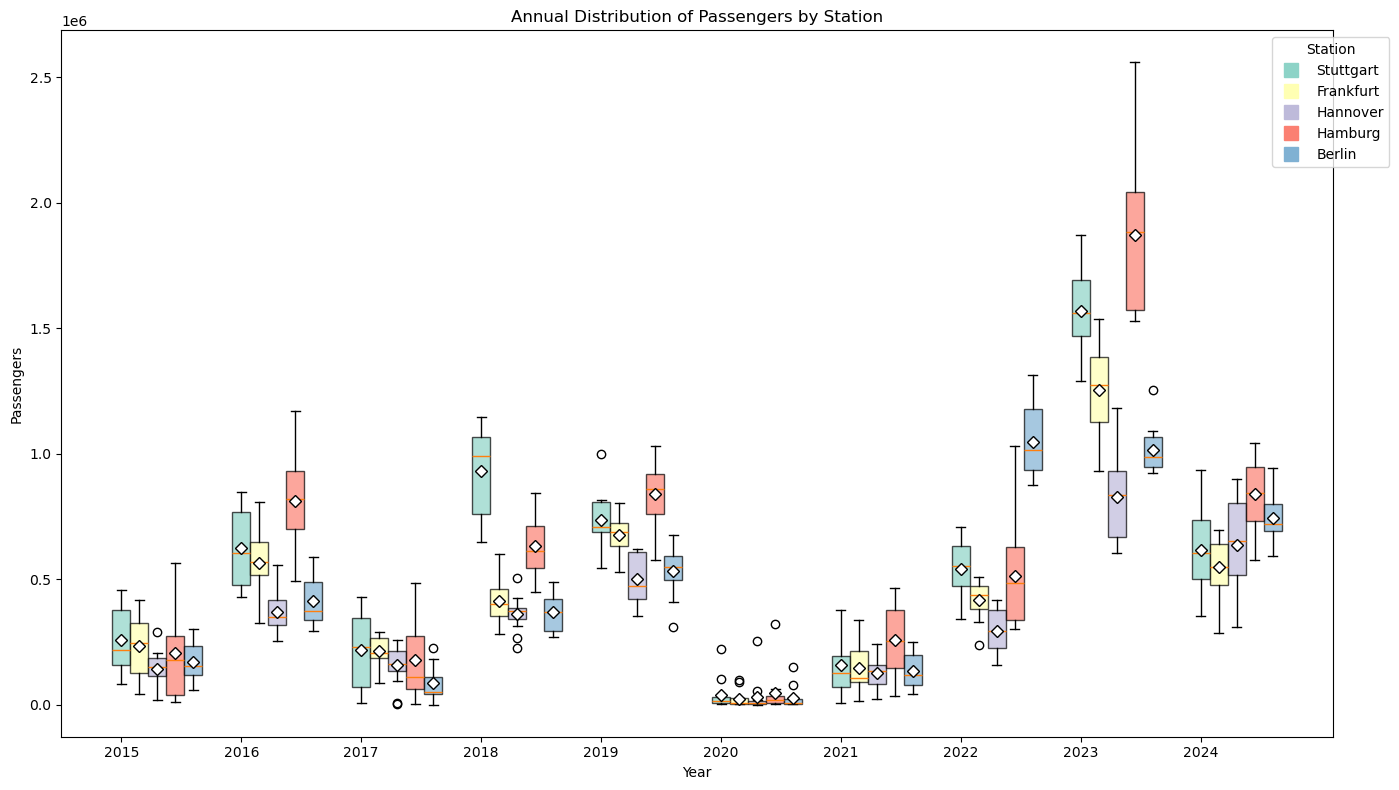

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

stations = data['Station'].unique()
years = sorted(data['Year'].unique())

fig, ax = plt.subplots(figsize=(14, 8))

colors = ['#8dd3c7', '#ffffb3', '#bebada', '#fb8072', '#80b1d3']

for i, station in enumerate(stations):
    station_data = [data[(data['Year'] == year) & (data['Station'] == station)]['Passengers'] for year in years]
    box = ax.boxplot(
        station_data,
        positions=[y + i * 0.15 for y in range(len(years))],
        widths=0.15,
        patch_artist=True,
        boxprops=dict(facecolor=colors[i % len(colors)], alpha=0.7),
        meanline=False,
        showmeans=True,
        meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black')
    )

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)
ax.set_xlabel('Year')
ax.set_ylabel('Passengers')
ax.set_title('Annual Distribution of Passengers by Station')

handles = [plt.Line2D([0], [0], color=color, marker='s', linestyle='None', markersize=10) for color in colors]
ax.legend(handles, stations, title='Station', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

### **Interpretation of the obtained results**

By analyzing the boxplots, we reach the conclusion that the year with less passengers was 2020. We can also reach the conclusion that after 2020 the number of passengers grew exponentially in Hamburg, reaching values around 2 million passengers in 2023.
To conclude, if we are using this analysis to check if there are any anomalies between stations, this boxplot will prove useful.

## **US17: Analysis of the cargo arriving at each station using all recorded data**

### **User Story Details**

As a Player, I want to perform an analysis of the cargo arriving at each station using all recorded data. Given the station’s name and cargo type specified by the user, a histogram will be created to visually represent the distribution of analyzed information, providing insights into cargo patterns.

### **Theoretical Explanation**

#### What does 'Binning' mean? 

Dividing the range of cargo‐weights (or counts) into contiguous, non‐overlapping intervals (“bins”) {𝐴1,𝐴2,…,𝐴𝑘}

#### What does Histogram mean? 

Histogram is a diagram consisting of rectangles whose area is proportional to the frequency of a variable and whose width is equal to the class interval.

#### What does 'Outlier Detection' mean? 

Techniques to flag observations that deviate markedly from the bulk of data.

### **Code for US17**

## **US18: Distribution Analysis of Trains, Passengers, and Mail**

### **User Story Details**

As a Player, I want to perform the analysis of train distribution, passengers, and mail across different stations. Using all recorded data, this distribution will be visually represented through three pie charts, providing a clear and comprehensive overview of how these elements are allocated among the stations.

### **Theoretical Explanation**

#### What is a Pie Chart?

A pie chart represents the relative frequency or percentage of categorical data. In our case, the categories we are interested in are the total number of train arrivals, total passenger counts, and total mail (in tons) recorded across all stations.

#### What is the Absolute Frequency?

The absolute frequency of a value  is simply the count of how many times that value (or any sort of data input) appears in a certain dataset.

#### What is the Relative Frequency?

The relative frequency of a value is the proportion of the total observations that that value (or any sort of data input) represents. It is obtained by dividing the absolute frequency by the total number of observations 𝑛.

### **Code for US18**

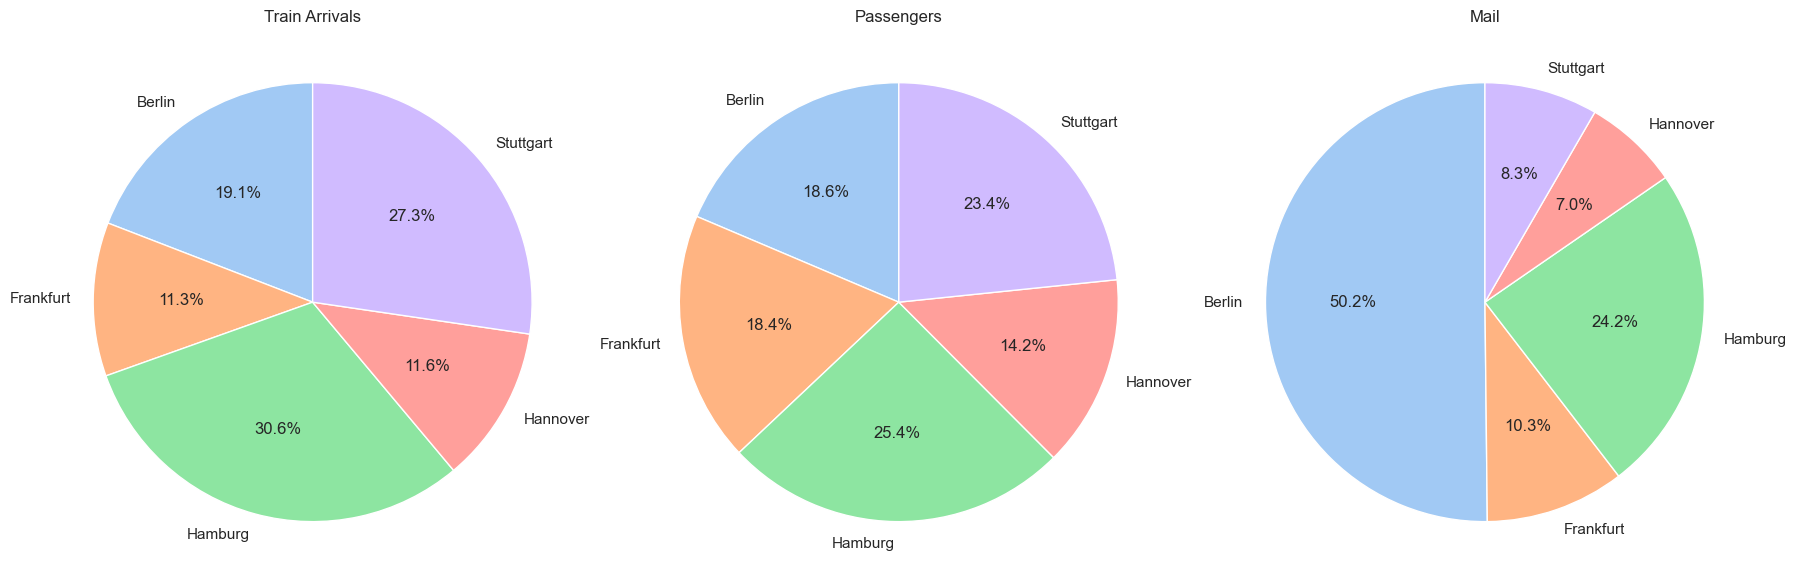

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

caminho_ficheiro = 'Stations_Data.csv'
df = pd.read_csv(caminho_ficheiro, sep=';')

# Transforming data into numbers, by replacing ',' with '.'
colunas = ['Arrivals', 'Passengers', 'Mail']
for col in colunas:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.'),
        errors='coerce'
    )

# Group the information by Station
df_agrupado = df.groupby('Station', as_index=False).agg({
    'Arrivals': 'sum',
    'Passengers': 'sum',
    'Mail': 'sum'
})

# Creating the figure with 3 pie charts in it
plt.figure(figsize=(18, 6))

categorias = ['Arrivals', 'Passengers', 'Mail']
titulos = ['Train Arrivals', 'Passengers', 'Mail']

for i, categoria in enumerate(categorias, 1):
    plt.subplot(1, 3, i)
    data = df_agrupado[['Station', categoria]].copy()
    
    plt.pie(
        data[categoria],
        labels=data['Station'],
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('pastel')
    )
    plt.axis('equal')
    plt.title(titulos[i - 1])

plt.tight_layout()
plt.show()


### **Interpretation of the obtained results**

By analyzing the three pie charts, we reach to the conclusion that Hamburg has the highest frequency of Train Arrivals and Passengers, however, Berlin comes out on top on Mail. Hannover has the lowest frequency in all of the pie charts. To conclude, if we are using this analysis to investigate the most profitable station, Hamburg and Stuttgart dominate on Train Arrivals and Passengers, however if we are talking about the Mail, Hamburg still is one of the best, but the most profitable is Berlin

# Conclusion

During the development of this project, by using mathematical concepts such as Quartiles, and data representation methods, like Pie Charts, we are able to statistically analyzie everything in the "Stations_Data.csv" file.

## Contribution (in %) of each team member

| Team Member          | Contribution (%) |
|----------------------|------------------|
| Diogo Silva (1241229)      | &#x5B; 33.4  &#x5D;   |
| Gonçalo Tavares (1241234)      | &#x5B; 33.3 &#x5D;   |
| Gonçalo Pinto (1241232)      | &#x5B; 33.3 &#x5D;   |

_Total: 100 %_
